# Phase 3, experiment 6: features that drift over time

**Why this experiment:** The three validation folds average about 0.98, but the public leaderboard is
about 0.947. So the test period (steps 36 to 49) is harder than any validation period, which suggests
the data changes over time. A tree model can only split on feature values it saw in training. If a
feature's values in the test period lie in a different range from the training period, the model's
rules for that feature may no longer mean the same thing.

**The one change in this experiment:** remove the raw features whose distribution changes most between
the training period and the period being predicted, and see whether that helps.

**How drift is measured:** For each feature, the Kolmogorov-Smirnov (KS) statistic compares its
distribution in two groups of rows. It is the largest gap between the two cumulative distributions:
0 means the two distributions are identical, 1 means they do not overlap at all. Only feature values
are used, never labels, so there is no leakage. Unlabeled rows are included because drift is about the
features, not the labels.

**Decisions:** carry forward the raw features only since degree and neighbour means did not
help on any fold or on the leaderboard. Try dropping drifting features.

Validation: the three expanding-window folds from notebook 07, default LightGBM.

## 1. Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

SEED = 42
DATA_DIR = "../data"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

raw_cols = [c for c in train.columns if c.startswith("feat_")]

# Labeled rows only (1 = illicit, 0 = licit), used for training and scoring
labeled = train[train["label"].notna()].copy()
labeled["label"] = labeled["label"].astype(int)

## 2. Which features drift between the training period and the test period?

In [2]:
def drift_scores(earlier, later):
    # KS statistic of every raw feature between two groups of rows, largest first.
    scores = {}
    for col in raw_cols:
        scores[col] = ks_2samp(earlier[col].values, later[col].values).statistic
    return pd.Series(scores).sort_values(ascending=False)

# Training period (steps 1-35, all rows) against test period (steps 36-49)
drift_test = drift_scores(train, test)

print("KS statistic over the 165 features:")
print(drift_test.describe().round(3))
drift_test.head(15).round(3)

KS statistic over the 165 features:
count    165.000
mean       0.187
std        0.201
min        0.000
25%        0.080
50%        0.131
75%        0.182
max        0.996
dtype: float64


feat_136    0.996
feat_101    0.995
feat_103    0.994
feat_100    0.992
feat_139    0.966
feat_137    0.929
feat_2      0.664
feat_109    0.648
feat_107    0.632
feat_106    0.550
feat_142    0.520
feat_115    0.517
feat_113    0.503
feat_151    0.485
feat_3      0.463
dtype: float64

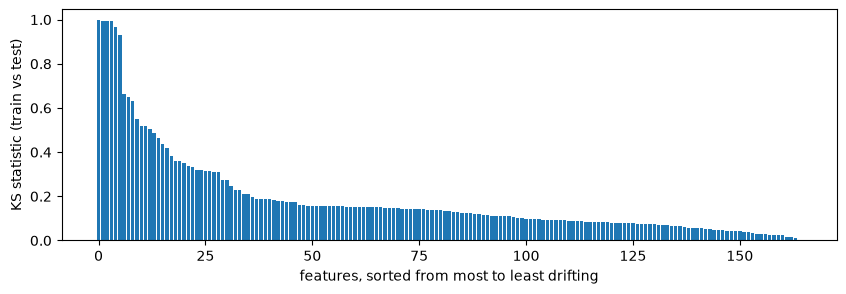

In [ ]:
# To see whether a few features stand apart from the rest
plt.figure(figsize=(10, 3))
plt.bar(range(len(drift_test)), drift_test.values)
plt.xlabel("features, sorted from most to least drifting")
plt.ylabel("KS statistic (train vs test)")
plt.show()

### What do the most drifting features look like over time?

The plot shows the average value of the six most drifting features in every time step, for train
(steps 1 to 35) and test (steps 36 to 49) together.

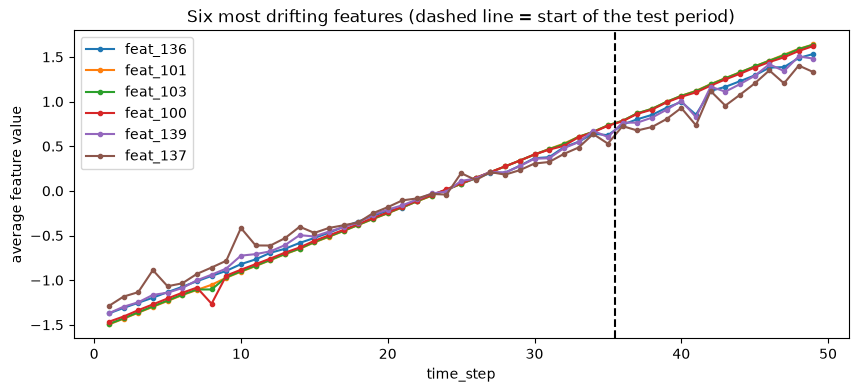

,train_min,train_max,test_min,test_max
feat_136,-13.09,4.12,-13.09,3.41
feat_101,-7.24,0.74,-2.63,1.66
feat_103,-7.22,0.74,-2.62,1.66
feat_100,-7.62,0.74,-2.57,1.64
feat_139,-12.87,3.97,-12.87,3.27
feat_137,-11.66,3.49,-11.66,3.49


In [4]:
top6 = list(drift_test.head(6).index)

# Average of each feature per time step, over train and test rows together
both = pd.concat([train[["time_step"] + top6], test[["time_step"] + top6]])
mean_by_step = both.groupby("time_step")[top6].mean()

ax = mean_by_step.plot(figsize=(10, 4), marker="o", markersize=3)
ax.axvline(35.5, color="black", linestyle="--")   # boundary between train and test steps
ax.set_ylabel("average feature value")
ax.set_title("Six most drifting features (dashed line = start of the test period)")
plt.show()

# For each of the six: the range of values in train and in test
pd.DataFrame({
    "train_min": train[top6].min(), "train_max": train[top6].max(),
    "test_min": test[top6].min(), "test_max": test[top6].max(),
}).round(2)

## 3. Does dropping drifting features help on the validation folds?

To copy what would be done for the test set, each fold measures drift between its own training steps
and its own validation steps (feature values only), drops the K most drifting features, then trains
and scores as usual. K = 0 is the baseline with all 165 features.

In [ ]:
FOLDS = [
    {"name": "fold 1", "train_last": 14, "valid_last": 21},
    {"name": "fold 2", "train_last": 21, "valid_last": 28},
    {"name": "fold 3", "train_last": 28, "valid_last": 35},
]

def split_fold(df, fold):
    # Return the (training rows, validation rows) of df for one fold.
    tr = df[df["time_step"] <= fold["train_last"]]
    va = df[(df["time_step"] > fold["train_last"]) & (df["time_step"] <= fold["valid_last"])]
    return tr, va

K_VALUES = [0, 6, 10, 20, 40]   

score_rows = []
fold_top6 = {}   # the six most drifting features in each fold

for fold in FOLDS:
    # Drift between this fold's training period and validation period (all rows, no labels used)
    period_tr, period_va = split_fold(train, fold)
    fold_drift = drift_scores(period_tr, period_va)
    fold_top6[fold["name"]] = list(fold_drift.head(6).index)

    tr, va = split_fold(labeled, fold)
    for k in K_VALUES:
        dropped = set(fold_drift.head(k).index)             # the k most drifting features
        cols = [c for c in raw_cols if c not in dropped]    

        model = lgb.LGBMClassifier(random_state=SEED, verbose=-1)
        model.fit(tr[cols], tr["label"])
        va_pred = model.predict_proba(va[cols])[:, 1]

        score_rows.append({"fold": fold["name"], "n_dropped": k,
                           "val_auc": roc_auc_score(va["label"], va_pred)})
    print("done:", fold["name"])

pd.DataFrame(fold_top6)

done: fold 1
done: fold 2
done: fold 3


,fold 1,fold 2,fold 3
0,feat_136,feat_136,feat_136
1,feat_101,feat_101,feat_101
2,feat_103,feat_103,feat_103
3,feat_100,feat_100,feat_100
4,feat_139,feat_139,feat_139
5,feat_137,feat_137,feat_137


In [6]:
fold_names = [f["name"] for f in FOLDS]
fold_table = pd.DataFrame(score_rows).pivot(index="n_dropped", columns="fold", values="val_auc")
fold_table["mean"] = fold_table[fold_names].mean(axis=1)

# Change compared with keeping all features (the n_dropped = 0 row)
change_table = fold_table - fold_table.loc[0]

print("Validation AUC:")
display(fold_table.round(4))
print("Change from the baseline (n_dropped = 0):")
display(change_table.round(4))

Validation AUC:


fold,fold 1,fold 2,fold 3,mean
n_dropped,,,,
0,0.9888,0.9572,0.9965,0.9808
6,0.9917,0.9451,0.9965,0.9777
10,0.9939,0.9448,0.9974,0.9787
20,0.9933,0.9476,0.9970,0.9793
40,0.9931,0.9373,0.9967,0.9757


Change from the baseline (n_dropped = 0):


fold,fold 1,fold 2,fold 3,mean
n_dropped,,,,
0,0.0000,0.0000,0.0000,0.0000
6,0.0029,-0.0122,0.0000,-0.0031
10,0.0052,-0.0124,0.0009,-0.0021
20,0.0045,-0.0096,0.0005,-0.0015
40,0.0043,-0.0199,0.0002,-0.0051


## 4. Retrain on all labeled rows and save a submission

The features dropped here are the ones with a KS statistic above 0.9 between the training period and
the test period, which means their test values barely overlap with their training values.

The folds may not show the effect of this change clearly (two of them are close to the maximum score),
so this submission is a way to check it against the test period.

In [7]:
KS_THRESHOLD = 0.9

final_dropped = list(drift_test[drift_test > KS_THRESHOLD].index)
final_cols = [c for c in raw_cols if c not in final_dropped]
print("Dropped features:", final_dropped)
print("Features used:", len(final_cols))

final_model = lgb.LGBMClassifier(random_state=SEED, verbose=-1)
final_model.fit(labeled[final_cols], labeled["label"])

test_pred = final_model.predict_proba(test[final_cols])[:, 1]
submission = pd.DataFrame({"index": test["index"], "target": test_pred})

# Format checks before saving
assert len(submission) == 15329, "wrong number of rows"
assert list(submission.columns) == ["index", "target"], "wrong columns"
assert submission["target"].notna().all(), "NaN in predictions"
assert (submission["index"].values == sample_sub["index"].values).all(), "index does not match sample submission"

SUB_PATH = "../submissions/sub04_drop_drift.csv"
submission.to_csv(SUB_PATH, index=False)
print("Saved", SUB_PATH)

Dropped features: ['feat_136', 'feat_101', 'feat_103', 'feat_100', 'feat_139', 'feat_137']
Features used: 159
Saved ../submissions/sub04_drop_drift.csv


## Results

- **Which features drift most between train and test?** Six features stand apart from the rest:
  `feat_136`, `feat_101`, `feat_103`, `feat_100`, `feat_139` and `feat_137`, with KS statistics of
  0.93 to 0.996. The next highest is `feat_2` at 0.66, and the median over all 165 features is 0.13.
  The same six are the most drifting features in all three validation folds.
- **What do the most drifting features look like over time?** Their average value rises steadily from
  one time step to the next across all 49 steps, so they behave like a measure of time. A KS value
  near 1 means the bulk of their test values lies above the bulk of their training values. The minimum
  and maximum ranges in train and test still overlap, because each feature has a few extreme values
  (for `feat_101`, `feat_103` and `feat_100` the test maximum of about 1.65 is above the training
  maximum of 0.74).
- **Does dropping drifting features help on the folds?** The folds do not give a clear answer. Dropping
  the six raises fold 1 by 0.0029, leaves fold 3 unchanged and lowers fold 2 by 0.0122, so the mean
  falls from 0.9808 to 0.9777. Dropping 10 or 20 features gives a similar picture (fold 1 up by about
  0.005, fold 2 down by about 0.010 to 0.012). Dropping 40 is worse on fold 2 (-0.020). All of the loss
  is in fold 2, which is dominated by step 24.
- **Decision: drop any features going forward?** No. Keep all 165 raw features, because dropping the
  six drifting features lowered both the fold mean and the public leaderboard score.
- **Public leaderboard AUC for `sub04_drop_drift.csv`:** 0.94365, against 0.94660 for the baseline with
  all 165 raw features (`sub01_baseline.csv`). That is 0.0030 lower. The size is at the edge of what
  could be noise on 30% of the test set, but the direction matches the folds, where the mean also fell
  by 0.0031. Neither measure supports dropping the six time-like features.
